# Bài 06 - Tổng hợp: PyTorch và Keras, RNN và các đối chứng

Notebook này không huấn luyện gì. Nó đọc các file `results/*.json` do notebook 03
(PyTorch) và 04 (Keras) ghi ra, dựng bảng so sánh và trả lời ba câu hỏi:

1. Trên cùng dữ liệu, cùng siêu tham số, hai framework có cho cùng kết quả không?
2. RNN, LSTM, GRU có hơn các đối chứng không cần hồi quy không?
3. Chênh lệch giữa các mô hình có lớn hơn chênh lệch do hạt giống ngẫu nhiên không?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import lab06_data as D

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 130, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 150)
R = D.load_results()
B = R["baselines"]
FW = ("torch", "keras")
FW_NAME = {"torch": "PyTorch", "keras": "Keras"}


def res(fw, task, model):
    return R["%s__%s__%s" % (fw, task, model)]


def ms(fw, task, model, key, fmt="%.4f"):
    m, s = res(fw, task, model)["summary"][key]
    return (fmt + " ± " + fmt) % (m, s)


def mean_time(fw, task, model):
    return np.mean([r["seconds"] for r in res(fw, task, model)["runs"]])


print(len(R), "file ket qua:", ", ".join(sorted(R)))

24 file ket qua: baselines, concept__memory, keras__churn__GRU, keras__churn__LSTM, keras__churn__MLP, keras__churn__RNN, keras__extra, keras__ret__GRU, keras__ret__LSTM, keras__ret__RNN, keras__vol__GRU, keras__vol__LSTM, keras__vol__RNN, torch__churn__GRU, torch__churn__LSTM, torch__churn__MLP, torch__churn__RNN, torch__extra, torch__ret__GRU, torch__ret__LSTM, torch__ret__RNN, torch__vol__GRU, torch__vol__LSTM, torch__vol__RNN


## 1. Churn

In [2]:
rows = [dict(mo_hinh="LogReg (sklearn)", **{"AUC " + FW_NAME[f]: "%.4f" % B["churn_logreg"]["roc_auc"] for f in FW},
             **{"F1 " + FW_NAME[f]: "%.4f" % B["churn_logreg"]["f1"] for f in FW})]
for m in ("MLP", "RNN", "LSTM", "GRU"):
    row = dict(mo_hinh=m)
    for f in FW:
        row["AUC " + FW_NAME[f]] = ms(f, "churn", m, "roc_auc")
    for f in FW:
        row["F1 " + FW_NAME[f]] = ms(f, "churn", m, "f1")
    for f in FW:
        row["tham so " + FW_NAME[f]] = res(f, "churn", m)["params"]
    for f in FW:
        row["giay/lan " + FW_NAME[f]] = "%.1f" % mean_time(f, "churn", m)
    rows.append(row)
churn_cmp = pd.DataFrame(rows).set_index("mo_hinh")
churn_cmp

,AUC PyTorch,AUC Keras,F1 PyTorch,F1 Keras,tham so PyTorch,tham so Keras,giay/lan PyTorch,giay/lan Keras
mo_hinh,,,,,,,,
LogReg (sklearn),0.7752,0.7752,0.5031,0.5031,NaN,NaN,NaN,NaN
MLP,0.8582 ± 0.0009,0.8539 ± 0.0026,0.6110 ± 0.0025,0.6121 ± 0.0054,417.0,417.0,6.3,27.3
RNN,0.8517 ± 0.0030,0.8534 ± 0.0053,0.5964 ± 0.0125,0.6129 ± 0.0113,1153.0,1121.0,13.1,16.2
LSTM,0.8429 ± 0.0036,0.8311 ± 0.0044,0.6136 ± 0.0047,0.5981 ± 0.0071,4513.0,4385.0,14.9,36.4
GRU,0.8414 ± 0.0033,0.8474 ± 0.0023,0.6054 ± 0.0132,0.6030 ± 0.0102,3393.0,3393.0,23.5,30.6


In [3]:
pt = np.array(res("torch", "churn", "LSTM")["p_test"])
pk = np.array(res("keras", "churn", "LSTM")["p_test"])
C = D.churn_splits()
thr_t = res("torch", "churn", "LSTM")["runs"][0]["metrics"]["threshold"]
thr_k = res("keras", "churn", "LSTM")["runs"][0]["metrics"]["threshold"]
agree = np.mean((pt >= thr_t) == (pk >= thr_k))
print("LSTM hat giong 42: tuong quan xac suat giua hai framework %.4f" % np.corrcoef(pt, pk)[0, 1])
print("ty le khach duoc hai framework xep cung lop: %.4f" % agree)
for m in ("MLP", "RNN", "LSTM", "GRU"):
    a_t = [r["metrics"]["roc_auc"] for r in res("torch", "churn", m)["runs"]]
    a_k = [r["metrics"]["roc_auc"] for r in res("keras", "churn", m)["runs"]]
    print("%-4s chenh AUC Keras - PyTorch: %+.4f | DLC theo hat giong: PyTorch %.4f, Keras %.4f"
          % (m, np.mean(a_k) - np.mean(a_t), np.std(a_t), np.std(a_k)))

LSTM hat giong 42: tuong quan xac suat giua hai framework 0.9033
ty le khach duoc hai framework xep cung lop: 0.9205
MLP  chenh AUC Keras - PyTorch: -0.0044 | DLC theo hat giong: PyTorch 0.0009, Keras 0.0026
RNN  chenh AUC Keras - PyTorch: +0.0017 | DLC theo hat giong: PyTorch 0.0030, Keras 0.0053
LSTM chenh AUC Keras - PyTorch: -0.0118 | DLC theo hat giong: PyTorch 0.0036, Keras 0.0044
GRU  chenh AUC Keras - PyTorch: +0.0060 | DLC theo hat giong: PyTorch 0.0033, Keras 0.0023


## 2. AMZN

In [4]:
rows = []
for name, m in B["ret"].items():
    rows.append(dict(mo_hinh=name, **{"RMSE " + FW_NAME[f]: "%.5f" % m["rmse"] for f in FW},
                     **{"dir_acc " + FW_NAME[f]: ("-" if np.isnan(m["dir_acc"]) else "%.4f" % m["dir_acc"]) for f in FW}))
for c in ("RNN", "LSTM", "GRU"):
    row = dict(mo_hinh=c)
    for f in FW:
        row["RMSE " + FW_NAME[f]] = ms(f, "ret", c, "rmse", "%.5f")
    for f in FW:
        row["dir_acc " + FW_NAME[f]] = ms(f, "ret", c, "dir_acc")
    rows.append(row)
ret_cmp = pd.DataFrame(rows).set_index("mo_hinh")
print("Bai toan 1 - loi suat phien ke tiep. Ty le phien tang trong test: %.4f" % B["up_share_test"])
ret_cmp

Bai toan 1 - loi suat phien ke tiep. Ty le phien tang trong test: 0.5082


,RMSE PyTorch,RMSE Keras,dir_acc PyTorch,dir_acc Keras
mo_hinh,,,,
Naive (loi suat 0),0.02376,0.02376,-,-
Trung binh train,0.02379,0.02379,0.5082,0.5082
Ridge (cua so 60 ngay),0.02387,0.02387,0.5041,0.5041
RNN,0.02385 ± 0.00007,0.02383 ± 0.00005,0.5095 ± 0.0097,0.5190 ± 0.0224
LSTM,0.02384 ± 0.00001,0.02384 ± 0.00001,0.5059 ± 0.0032,0.5063 ± 0.0046
GRU,0.02387 ± 0.00003,0.02388 ± 0.00006,0.5072 ± 0.0006,0.5050 ± 0.0119


In [5]:
rows = []
for name, m in B["vol"].items():
    rows.append(dict(mo_hinh=name, **{"R2 " + FW_NAME[f]: "%.4f" % m["r2"] for f in FW},
                     **{"RMSE " + FW_NAME[f]: "%.5f" % m["rmse"] for f in FW}))
for c in ("RNN", "LSTM", "GRU"):
    row = dict(mo_hinh=c)
    for f in FW:
        row["R2 " + FW_NAME[f]] = ms(f, "vol", c, "r2")
    for f in FW:
        row["RMSE " + FW_NAME[f]] = ms(f, "vol", c, "rmse", "%.5f")
    for f in FW:
        row["giay/lan " + FW_NAME[f]] = "%.1f" % mean_time(f, "vol", c)
    rows.append(row)
vol_cmp = pd.DataFrame(rows).set_index("mo_hinh")
print("Bai toan 2 - bien dong 5 phien toi")
vol_cmp

Bai toan 2 - bien dong 5 phien toi


,R2 PyTorch,R2 Keras,RMSE PyTorch,RMSE Keras,giay/lan PyTorch,giay/lan Keras
mo_hinh,,,,,,
Bien dong 20 ngay qua,-0.0219,-0.0219,0.01148,0.01148,NaN,NaN
Trung binh train,-0.5135,-0.5135,0.01397,0.01397,NaN,NaN
Ridge (cua so 60 ngay),0.2732,0.2732,0.00968,0.00968,NaN,NaN
RNN,0.2554 ± 0.0160,0.2457 ± 0.0190,0.00980 ± 0.00010,0.00986 ± 0.00012,24.5,28.7
LSTM,0.2433 ± 0.0154,0.2830 ± 0.0108,0.00987 ± 0.00010,0.00961 ± 0.00007,26.9,31.1
GRU,0.2766 ± 0.0038,0.2567 ± 0.0035,0.00966 ± 0.00003,0.00979 ± 0.00002,72.5,79.1


## 3. Hình tổng hợp

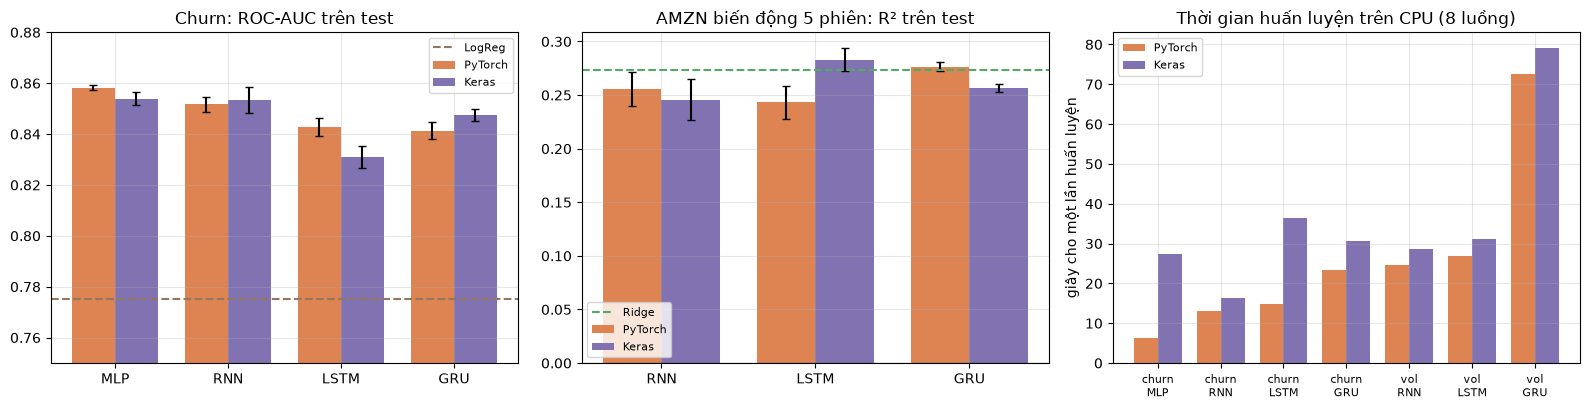

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
models = ("MLP", "RNN", "LSTM", "GRU")
x = np.arange(len(models))
for j, f in enumerate(FW):
    mean = [res(f, "churn", m)["summary"]["roc_auc"][0] for m in models]
    std = [res(f, "churn", m)["summary"]["roc_auc"][1] for m in models]
    axes[0].bar(x + (j - 0.5) * 0.38, mean, 0.38, yerr=std, capsize=3,
                label=FW_NAME[f], color=["#DD8452", "#8172B2"][j])
axes[0].axhline(B["churn_logreg"]["roc_auc"], c="#937860", ls="--", label="LogReg")
axes[0].set_xticks(x, models)
axes[0].set_ylim(0.75, 0.88)
axes[0].set_title("Churn: ROC-AUC trên test")
axes[0].legend(fontsize=8)

cells = ("RNN", "LSTM", "GRU")
x = np.arange(len(cells))
for j, f in enumerate(FW):
    mean = [res(f, "vol", c)["summary"]["r2"][0] for c in cells]
    std = [res(f, "vol", c)["summary"]["r2"][1] for c in cells]
    axes[1].bar(x + (j - 0.5) * 0.38, mean, 0.38, yerr=std, capsize=3,
                label=FW_NAME[f], color=["#DD8452", "#8172B2"][j])
ridge_name = [k for k in B["vol"] if k.startswith("Ridge")][0]
axes[1].axhline(B["vol"][ridge_name]["r2"], c="#55A868", ls="--", label="Ridge")
axes[1].axhline(0, c="k", lw=0.8)
axes[1].set_xticks(x, cells)
axes[1].set_title("AMZN biến động 5 phiên: R² trên test")
axes[1].legend(fontsize=8)

tasks = [("churn", m) for m in models] + [("vol", c) for c in cells]
labels = ["churn\n" + m for m in models] + ["vol\n" + c for c in cells]
x = np.arange(len(tasks))
for j, f in enumerate(FW):
    axes[2].bar(x + (j - 0.5) * 0.38, [mean_time(f, t, m) for t, m in tasks], 0.38,
                label=FW_NAME[f], color=["#DD8452", "#8172B2"][j])
axes[2].set_xticks(x, labels, fontsize=8)
axes[2].set_ylabel("giây cho một lần huấn luyện")
axes[2].set_title("Thời gian huấn luyện trên CPU (8 luồng)")
axes[2].legend(fontsize=8)
fig.tight_layout()
fig.savefig(D.RESULTS / "fig_compare.png", bbox_inches="tight")
plt.show()

## 4. Ghi bảng tổng hợp

In [7]:
rows = []
for f in FW:
    for task, keys in (("churn", ("roc_auc", "pr_auc", "f1")), ("ret", ("rmse", "dir_acc")),
                       ("vol", ("rmse", "r2"))):
        for m in (("MLP", "RNN", "LSTM", "GRU") if task == "churn" else cells):
            r = res(f, task, m)
            rows.append(dict(framework=FW_NAME[f], task=task, model=m, params=r["params"],
                             seconds=round(mean_time(f, task, m), 1),
                             epochs=round(np.mean([x["epochs"] for x in r["runs"]]), 1),
                             **{k: round(r["summary"][k][0], 5) for k in keys},
                             **{k + "_std": round(r["summary"][k][1], 5) for k in keys}))
summary = pd.DataFrame(rows)
summary.to_csv(D.RESULTS / "summary.csv", index=False)
with open(D.RESULTS / "summary.md", "w", encoding="utf-8") as fh:
    fh.write("# Bai 06 - bang tong hop\n\n")
    for title, df in (("Churn", churn_cmp), ("AMZN loi suat", ret_cmp), ("AMZN bien dong", vol_cmp)):
        fh.write("## %s\n\n%s\n\n" % (title, df.to_markdown()))
print(summary.to_string(index=False))

framework  task model  params  seconds  epochs  roc_auc  pr_auc      f1  roc_auc_std  pr_auc_std  f1_std    rmse  dir_acc  rmse_std  dir_acc_std      r2  r2_std
  PyTorch churn   MLP     417      6.3    32.0  0.85823 0.69693 0.61100      0.00093     0.00278 0.00255     NaN      NaN       NaN          NaN     NaN     NaN
  PyTorch churn   RNN    1153     13.1    26.7  0.85170 0.67773 0.59643      0.00299     0.00544 0.01246     NaN      NaN       NaN          NaN     NaN     NaN
  PyTorch churn  LSTM    4513     14.9    29.7  0.84290 0.67290 0.61360      0.00361     0.00532 0.00474     NaN      NaN       NaN          NaN     NaN     NaN
  PyTorch churn   GRU    3393     23.5    25.3  0.84137 0.67060 0.60540      0.00331     0.00523 0.01319     NaN      NaN       NaN          NaN     NaN     NaN
  PyTorch   ret   RNN    1217     13.5    11.0      NaN     NaN     NaN          NaN         NaN     NaN 0.02385  0.50951   0.00007      0.00967     NaN     NaN
  PyTorch   ret  LSTM    4769     